# 02 · Baselines: TF-IDF, BM25 and Dense Retrieval

**Project:** AI-Powered Semantic Product Discovery & Shopping Concierge · **Author:** Maaz Amjad

## Problem
Before adding query parsing, filtering and personalization, we need the reference points they must beat:
lexical search (**S1 TF-IDF**, **S2 BM25**) and unfiltered semantic search (**S3 BGE + FAISS**).

## Data
The 10,000-product Appliances catalog from `01_eda`, with each `product_text` embedded once by
`BAAI/bge-small-en-v1.5` (384-dimensional, L2-normalized) and saved in `artifacts/`.

## Approach
All retrievers live in `src/retrieve.py` and share one tokenizer that keeps part numbers intact
(`da29-00020b`, `w10425238`). We check that the dense index returns sensible neighbours, compare the three
systems qualitatively on **dev** queries only (test queries stay unseen until the final evaluation), and measure
how much their results overlap and how fast they are.

## Results (summary)
Relevance metrics need the pooled relevance labels (Phase 6), so this notebook reports sanity checks,
overlap and latency only. All three systems answer in milliseconds on CPU, and they return largely
*different* products: the comparison in the final evaluation is meaningful.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import load_config, set_seed
from src.data import load_catalog
from src.embed import encode_query, load_embeddings, load_model, use_query_instruction
from src.retrieve import BM25Retriever, DenseIndex, TfidfRetriever

set_seed(42)
cfg = load_config()
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.max_colwidth", 70)

catalog = load_catalog()
embeddings, product_ids = load_embeddings()
assert (product_ids == catalog.product_id.to_numpy()).all(), "embedding rows must match catalog rows"
queries = pd.read_csv(PROJECT_ROOT / "eval" / "queries.csv")
dev = queries[queries.split == "dev"].reset_index(drop=True)
print(f"catalog {catalog.shape}, embeddings {embeddings.shape} {embeddings.dtype}, dev queries {len(dev)}")

catalog (10000, 9), embeddings (10000, 384) float32, dev queries 10


## 1. Build the three retrievers

In [2]:
texts = catalog.product_text.tolist()
build_s = {}
t = time.perf_counter(); tfidf = TfidfRetriever(texts); build_s["S1 TF-IDF"] = time.perf_counter() - t
t = time.perf_counter(); bm25 = BM25Retriever(texts); build_s["S2 BM25"] = time.perf_counter() - t
t = time.perf_counter(); dense = DenseIndex(embeddings); build_s["S3 Dense"] = time.perf_counter() - t
model = load_model(cfg["embedding"]["model"])
USE_PREFIX = use_query_instruction(cfg)  # "auto" = BGE prefix on until the dev comparison (spec 6)
print({k: f"{v:.2f}s" for k, v in build_s.items()}, "| TF-IDF vocabulary:", len(tfidf.vectorizer.vocabulary_))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'S1 TF-IDF': '1.35s', 'S2 BM25': '1.35s', 'S3 Dense': '0.01s'} | TF-IDF vocabulary: 74145


**Insight.** Building the lexical indexes takes seconds and the FAISS index is instant, because the product
embeddings were computed once and saved (`python -m src.embed`). Nothing here needs a GPU.

## 2. Sanity check: nearest neighbours of sample products
If the embeddings are sensible, a product's nearest neighbours should be the same kind of product.

In [3]:
def neighbours(row: int, k: int = 4) -> pd.DataFrame:
    hits = dense.search(embeddings[row], k + 1)
    hits = hits[hits.row != row].head(k)
    return catalog.loc[hits.row, ["title", "category"]].assign(cosine=hits.score.round(3).to_numpy())

for row in catalog.sample(3, random_state=42).index:
    print(f"\nQUERY PRODUCT: {catalog.title[row][:90]}  [{catalog.category[row]}]")
    display(neighbours(row))


QUERY PRODUCT: Drain Pump W10425238, AP6023357, PS11756700, W10605427 Washing Machine Drain Pump Compatib  [Washer Parts & Accessories]


,title,category,cosine
3386,"Primeco W10130913, W10730972, Compatible for whirlpool Washer Drai...",Washer Parts & Accessories,0.861
9483,2023 Upgrade W10276397 Washer Drain Pump by Beaquicy - 2 Years WAR...,Washer Parts & Accessories,0.854
4030,Whirlpool 25001052 Pump Assembly for Washer,Washer Parts & Accessories,0.851
2263,W10130913 Drain Pump & WP356138 Spring Tension Hose Clamp by Parts...,Washer Parts & Accessories,0.849



QUERY PRODUCT: GE WR17X11419 Bucket and Auger Assembly for Refrigerator  [Parts & Accessories]


,title,category,cosine
6878,GE WR17X11429 Bucket and Auger Assembly for Refrigerator,Parts & Accessories,0.988
7541,GE WR17X11263 Genuine OEM Ice Bucket Auger Assembly for GE Refrige...,Parts & Accessories,0.911
7564,"GE WR17X12138 Refrigerator Ice Bucket and Auger Assembly, White",Refrigerator Parts & Accessories,0.909
3449,GE WR17X11618 Filter Assembly and Tube for Refrigerator,Parts & Accessories,0.905



QUERY PRODUCT: 3387134 & 3392519 - Cycling Thermostat & Thermal Fuse for Whirlpool & Kenmore Dryer  [Dryer Parts & Accessories]


,title,category,cosine
3401,3387134 Cycling Thermostat 3977393 & 3392519 Dryer Thermal Fuse 39...,Dryer Parts & Accessories,0.941
829,Edgewater Parts 3387134 & 3392519 Cycling Thermostat & Thermal Fus...,Dryer Parts & Accessories,0.937
8991,3387134 Cycling Thermostat 2 * 3392519 Dryer Thermal Fuse 3977767 ...,Dryer Parts & Accessories,0.922
5940,3387134 Cycling Thermostat 3392519 Dryer Thermal Fuse 3977767 High...,Dryer Parts & Accessories,0.920


**Insight.** Neighbours share the product type and often the compatible appliance brand, even when
titles use different words. The spec's done-when for `embed.py` (reloadable embeddings, sensible neighbours) holds.
Neighbour cosine values sit in a narrow high band (about 0.85 to 0.99), which is typical for BGE; that is why the ranking
stage min-max normalizes scores per query before mixing them with personalization.

## 3. Side-by-side on dev queries
One query per behaviour we care about: compatibility wording, a descriptive need, and an exact part number.

In [4]:
def run_all(text: str, k: int = 5) -> pd.DataFrame:
    qv = encode_query(text, model, use_instruction=USE_PREFIX)
    out = {}
    for name, res in [("S1 TF-IDF", tfidf.search(text, k)), ("S2 BM25", bm25.search(text, k)),
                      ("S3 Dense", dense.search(qv, k))]:
        out[name] = catalog.title.iloc[res.row].str[:60].to_numpy()
    return pd.DataFrame(out, index=range(1, k + 1))

for qid in ["q12", "q13", "q21"]:
    text = dev.set_index("query_id").text[qid]
    print(f"\n{qid}: {text}")
    display(run_all(text))


q12: compatible water filter for a Samsung fridge, any brand is fine


,S1 TF-IDF,S2 BM25,S3 Dense
1,water filter,Replacement for Samsung DA97-08006A-B Refrigerator Water Fil,"DA29-00020B Refrigerator Water Filter, Compatible with Samsu"
2,"DA29-00020B Refrigerator Water Filter, Compatible with Samsu",Tier1 Replacement for Samsung DA29-10105J Inline Water Filte,"SAMSUNG Genuine Filters for Refrigerator Water and Ice, Carb"
3,Denali Pure Replacement for Samsung DA97-08006A-B Refrigerat,2-Pack Replacement for GEN11042FR-08 Refrigerator Water Filt,"SAMSUNG Genuine Filters for Refrigerator Water and Ice, Carb"
4,"Samsung DA29-00020B, DA29-00020A, HAF-CIN EXP Premium Genuin",3-Pack Replacement for ADQ72910902 Refrigerator Water Filter,Samsung Products DA29-00003F Aqua-Pure Plus Refrigerator Wat
5,Replacement for Samsung DA97-08006A-B Refrigerator Water Fil,"Refresh Replacement for Samsung Aqua-Pure Plus DA29-00003G,",K&J Replacement Samsung Compatible Refrigerator Water Filter



q13: something to stop my dryer from squeaking


,S1 TF-IDF,S2 BM25,S3 Dense
1,3 X Replacement Part for Keurig My K-cup Reusable Coffee Fil,Upgraded 4392065 Dryer Repair Kit - 349241T Dryer Rear Drum,Anti Vibration Pads for Washing Machine – 4-Piece Set Anti V
2,PureWater Filters Pack of 4 Filter Basket Replacements Desig,AGM75510755 4581EL2002H 4581EL2002C LG Dryer Roller Assembly,Super Silent Washer and Dryer Antivibration Pads – Best Wash
3,"Replacement of Disposable Coffee Filters, Compatible with Un",Prop and Stop (Original US Brand) - Front Load Washer Door H,"STOP SHAKES Anti Vibration Pads for washer machine, washer a"
4,"Keurig My K-Cup Universal Reusable Ground Coffee Filter, Com",Washing Machine Rubber Feet Pads | Anti-Vibration & Anti-Wal,"4 Pack Anti Vibration Pads for Washing Machine - Durable, Sh"
5,GENUINE Whirlpool W10195622 Stop Replacement,"4392065 Dryer Repair Kit with 341241 Dryer Belt, 349241t, 69",ALL-GRIP | Anti-Vibration Pads Washer Washing Dryer Drying M



q21: 3387134 cycling thermostat


,S1 TF-IDF,S2 BM25,S3 Dense
1,3387134 & 3392519 - Cycling Thermostat & Thermal Fuse for Wh,"279838 Dryer Heating Element 3403585, 3387134 Cycling Thermo",Lifetime Warranty WP3387134 3387134 Dryer Cycling Thermostat
2,Edgewater Parts 3387134 & 3392519 Cycling Thermostat & Therm,prime&swift 3387134 Dryer Cycling Thermostat&3392519 Thermal,3387134 Cycling Thermostat 2 * 3392519 Dryer Thermal Fuse 39
3,"279838 Dryer Heating Element 3403585, 3387134 Cycling Thermo",3387134 Cycling Thermostat 3977393 & 3392519 Dryer Thermal F,3387134 & 3392519 - Cycling Thermostat & Thermal Fuse for Wh
4,Lifetime 3387134 AND 3392519 DRYER CYCLING THERMOSTAT & THER,Edgewater Parts 3387134 & 3392519 Cycling Thermostat & Therm,PS344510 AND PS345113 DRYER CYCLING THERMOSTAT WITH INTERNAL
5,Canamax COMPLETE 3977393 Thermal Cut-Off Switch 3977767 High,3387134 & 3392519 - Cycling Thermostat & Thermal Fuse for Wh,3387134 & 3392519 Dryer Cycling Thermostat & Thermal Fuse Re


**Insight.** The results did not all go the way we expected:
- **q12 (compatibility wording):** dense retrieval returns Samsung-compatible and genuine Samsung filters; TF-IDF's
  top hit is a product literally titled "water filter", and BM25 mixes in replacements for other fridge models
  (part numbers GEN11042FR-08 and ADQ72910902, which are not Samsung parts).
- **q13 (descriptive need, "stop my dryer from squeaking"):** BM25 does best here, finding dryer repair kits and a
  roller assembly (the parts that actually cause squeaking). Dense retrieval returns anti-vibration pads, mostly for
  washing machines, with two listings that also mention dryers: related to noise and vibration, but they address
  shaking rather than the worn rollers or belts that cause a squeak. TF-IDF fails outright
  (coffee filters, matched on "stop"). So "dense wins on descriptive queries" is a hypothesis to test, not a given.
- **q21 (exact part number):** all three systems find `3387134` thermostats; dense retrieval matches the
  part number about as well as the lexical systems, because part numbers are also present in the embedded text.

These are impressions from three dev queries; the measured comparison comes in Phase 9.

## 4. How different are the systems? Overlap of top-10 results

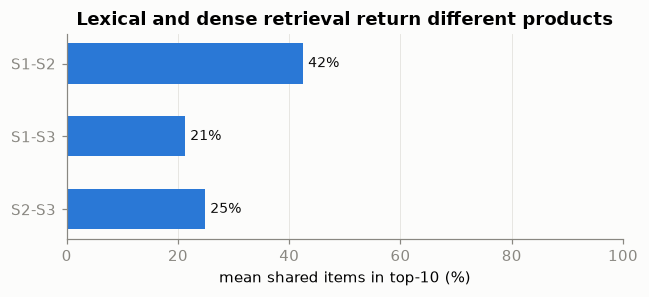

,mean overlap@10
S1-S2,0.424
S1-S3,0.212
S2-S3,0.248


In [5]:
def top10_sets(text: str) -> dict[str, set]:
    qv = encode_query(text, model, use_instruction=USE_PREFIX)
    return {"S1": set(tfidf.search(text, 10).row), "S2": set(bm25.search(text, 10).row),
            "S3": set(dense.search(qv, 10).row)}

pairs = [("S1", "S2"), ("S1", "S3"), ("S2", "S3")]
rows = []
for text in queries.text:  # overlap uses no labels, so all queries are safe to use
    s = top10_sets(text)
    rows.append({f"{a}-{b}": len(s[a] & s[b]) / 10 for a, b in pairs})
overlap = pd.DataFrame(rows).mean()

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(overlap.index[::-1], overlap.values[::-1] * 100, color=BLUE, height=0.55)
for y, v in enumerate(overlap.values[::-1] * 100):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", color=INK, fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("mean shared items in top-10 (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Lexical and dense retrieval return different products")
plt.tight_layout(); plt.show()
overlap.round(3).to_frame("mean overlap@10")

**Insight.** TF-IDF and BM25 share about 42 % of their top-10 results, roughly twice as much as either shares with
dense retrieval (21 % and 25 %). Because
the systems return largely different products, pooling the top-10 of every system (Phase 6) yields a richer pool
of candidates to label, and the S1 vs S3 comparison measures a real difference rather than noise.

## 5. Latency per query

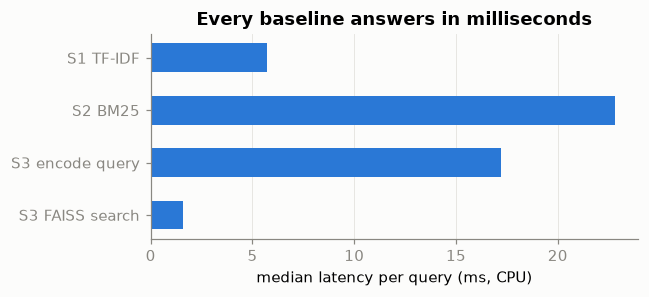

,median ms,p95 ms
S1 TF-IDF,5.7,9.1
S2 BM25,22.8,47.9
S3 encode query,17.2,18.9
S3 FAISS search,1.6,2.2


In [6]:
def timed(fn, reps: int = 3) -> float:
    times = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return float(np.median(times)) * 1000

lat = {"S1 TF-IDF": [], "S2 BM25": [], "S3 encode query": [], "S3 FAISS search": []}
for text in dev.text:
    lat["S1 TF-IDF"].append(timed(lambda: tfidf.search(text, 10)))
    lat["S2 BM25"].append(timed(lambda: bm25.search(text, 10)))
    lat["S3 encode query"].append(timed(lambda: encode_query(text, model, use_instruction=USE_PREFIX)))
    qv = encode_query(text, model, use_instruction=USE_PREFIX)
    lat["S3 FAISS search"].append(timed(lambda: dense.search(qv, 10)))
lat = pd.DataFrame(lat)
summary = lat.agg(["median", lambda s: s.quantile(0.95)]).T.round(1)
summary.columns = ["median ms", "p95 ms"]

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(summary.index[::-1], summary["median ms"][::-1], color=BLUE, height=0.55)
ax.set_xlabel("median latency per query (ms, CPU)"); ax.grid(axis="y", visible=False)
ax.set_title("Every baseline answers in milliseconds")
plt.tight_layout(); plt.show()
summary

**Insight.** Every baseline answers well inside the NFR-1 budget (retrieval + filtering + ranking p95 < 500 ms).
For the dense system the cost is dominated by *encoding the query* with the transformer, not by the exact FAISS
search over 10,000 vectors. BM25 is the slowest lexical system because `rank_bm25` scores every document in Python.
End-to-end latency will be dominated by the two Gemini calls added in later phases.

## Takeaways
1. Embeddings are sound (sensible neighbours) and persisted; S1, S2 and S3 run on all 25 queries.
2. The systems retrieve different products, so the ablation will be informative.
3. On three dev queries no system dominates: dense handles compatibility wording well, BM25 handled the
   descriptive "squeaking" query best, and all three find exact part numbers. Only the labelled evaluation can settle it.
4. Embedding the catalog is a one-off step outside this notebook (`python -m src.embed`, which printed
   `embeddings (10000, 384) float32 in 1633s`, about 27 minutes on this CPU); the result is cached in `artifacts/`.
5. The BGE query prefix is on (`query_instruction: auto`). Spec 6 asks to compare it with no prefix on dev
   queries; that needs relevance labels and is done in Phase 6.
6. Next: query parsing and hard filters (S4 post-filter vs S5 filter-first).